In [34]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [35]:
# Use the notebook location to determine project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

DATA_DIR = BASE_DIR / "data"
MODEL_DIR = BASE_DIR / "models"
PLOT_DIR = BASE_DIR / "visualizations"
REPORT_DIR = BASE_DIR / "reports"

for folder in [DATA_DIR, MODEL_DIR, PLOT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project Root:", BASE_DIR)
print("Data Directory:", DATA_DIR)
print("Models Directory:", MODEL_DIR)
print("Visualizations:", PLOT_DIR)
print("Reports:", REPORT_DIR)

Project Root: d:\Veda_tech_internship\ecommerce-customer-segmentation
Data Directory: d:\Veda_tech_internship\ecommerce-customer-segmentation\data
Models Directory: d:\Veda_tech_internship\ecommerce-customer-segmentation\models
Visualizations: d:\Veda_tech_internship\ecommerce-customer-segmentation\visualizations
Reports: d:\Veda_tech_internship\ecommerce-customer-segmentation\reports


In [36]:
DATA_PATH = DATA_DIR / "data.csv"

df = pd.read_csv(
    DATA_PATH,
    encoding="ISO-8859-1"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [37]:
print("Dataset Path:", DATA_PATH)
print("Path Exists:", DATA_PATH.exists())
print("Is File:", DATA_PATH.is_file())
print("Is Directory:", DATA_PATH.is_dir())

Dataset Path: d:\Veda_tech_internship\ecommerce-customer-segmentation\data\data.csv
Path Exists: True
Is File: True
Is Directory: False


In [38]:
for item in DATA_DIR.iterdir():
    print(
        item.name,
        "| File:", item.is_file(),
        "| Directory:", item.is_dir()
    )

data.csv | File: True | Directory: False


In [39]:
for item in DATA_DIR.iterdir():
    print(
        item.name,
        "| File:", item.is_file(),
        "| Directory:", item.is_dir()
    )

data.csv | File: True | Directory: False


In [40]:
for item in DATA_DIR.iterdir():
    print(item.name, item.is_file(), item.is_dir())

data.csv True False


In [41]:
DATA_PATH = DATA_DIR / "data.csv"

df = pd.read_csv(DATA_PATH, encoding="ISO-8859-1")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [42]:

# STEP 4: DATA CLEANING & PREPROCESSING

# Create a copy of original dataset
df_clean = df.copy()

print("Original Dataset Shape:", df_clean.shape)

# 1. Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# 2. Clean Description column
df_clean["Description"] = df_clean["Description"].astype("string").str.strip()

# 3. Convert columns into correct data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"], errors="coerce"
)

# 4. Remove rows with missing important values
df_clean.dropna(
    subset=["InvoiceNo", "StockCode", "Description",
            "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"],
    inplace=True
)

# 5. Remove cancelled transactions
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# 6. Remove invalid quantity and price
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# 7. Remove duplicate records
df_clean.drop_duplicates(inplace=True)

# 8. Convert CustomerID into integer
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# 9. Calculate total transaction amount
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("\nCleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Preview:")
display(df_clean.head())


Original Dataset Shape: (541909, 8)

Cleaned Dataset Shape: (392692, 9)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Cleaned Dataset Preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


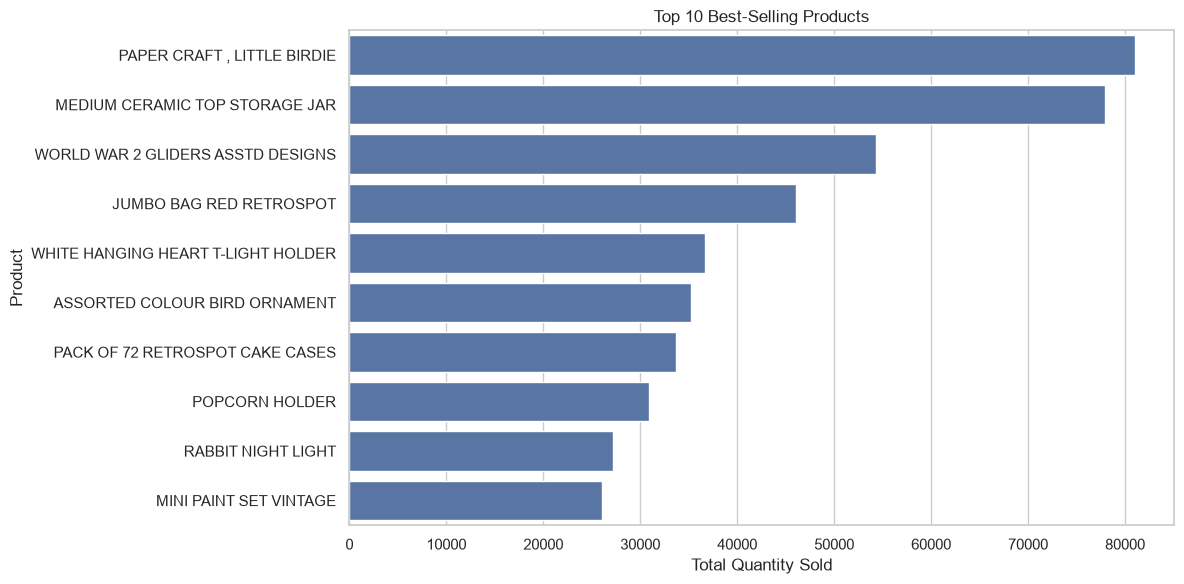

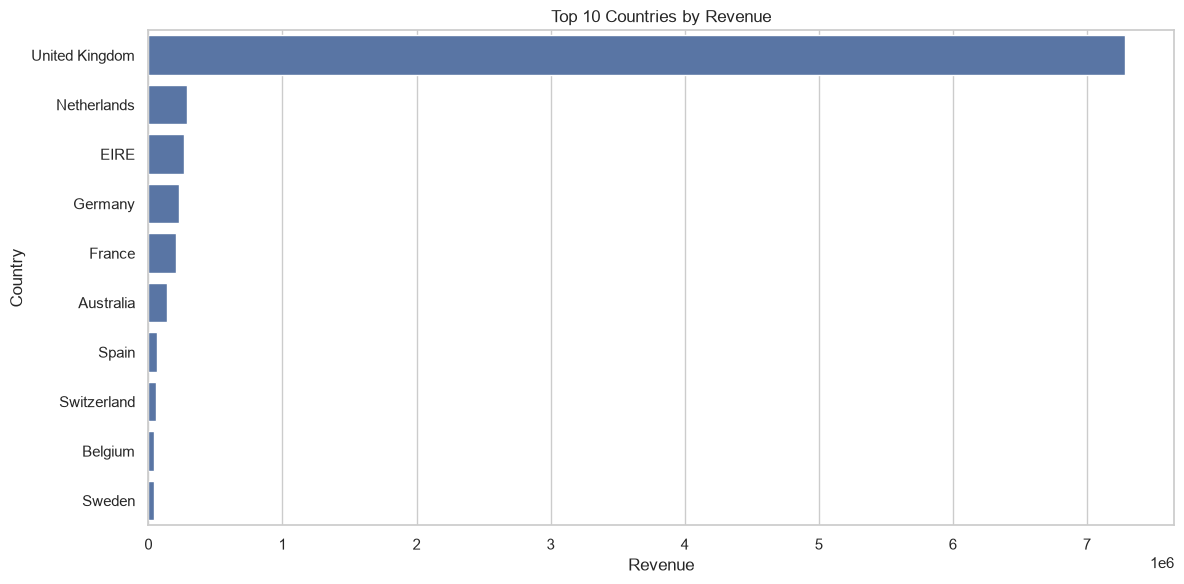

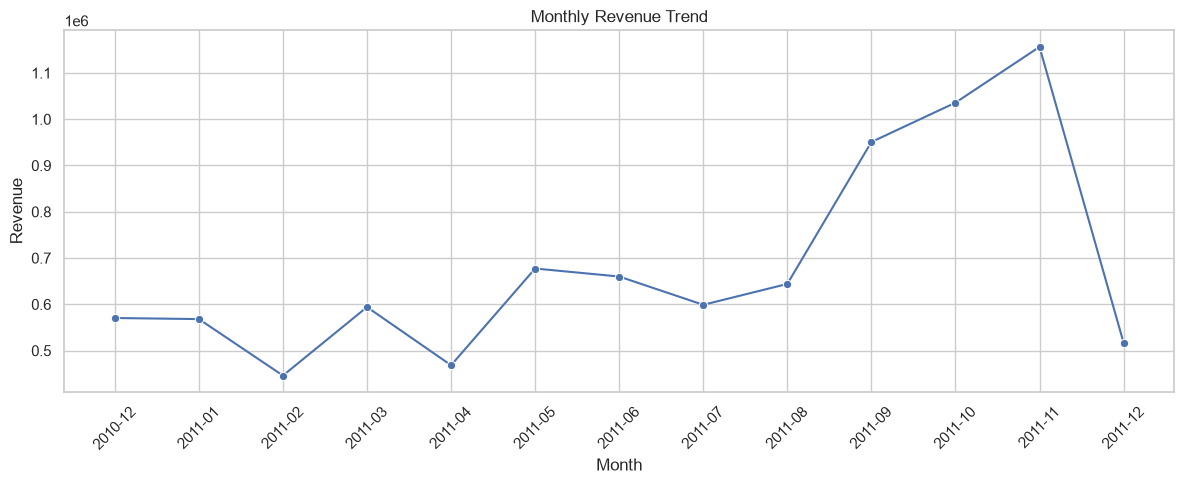

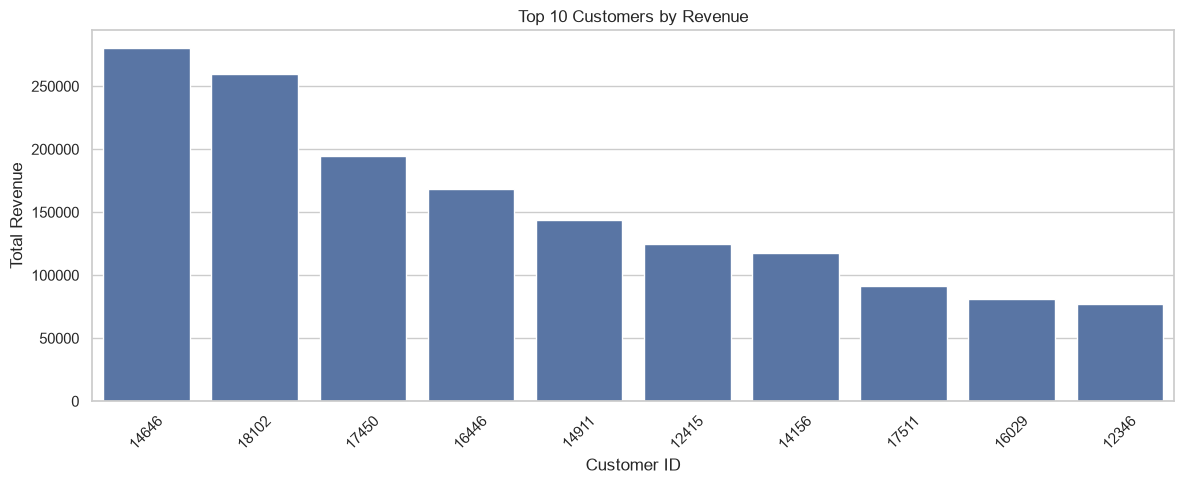

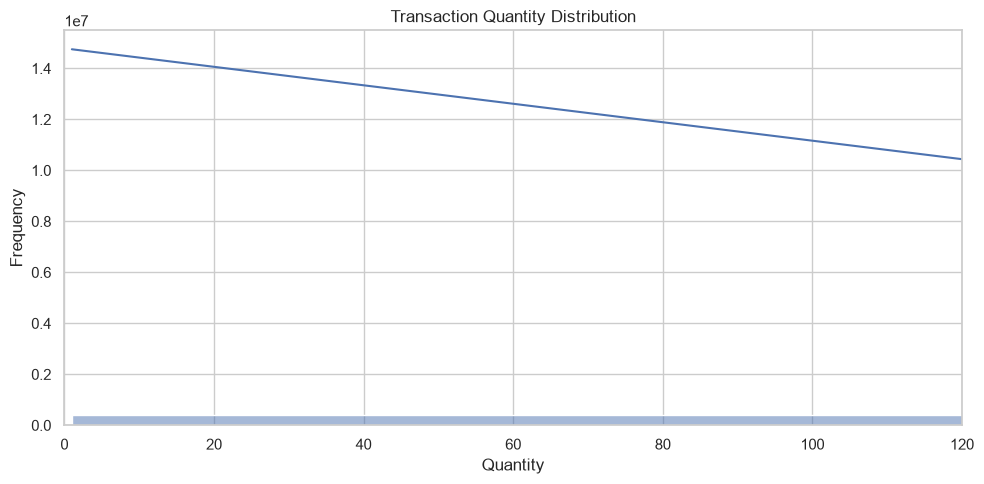

EDA Completed Successfully!


In [43]:

# STEP 5: EXPLORATORY DATA ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Top 10 Best-Selling Products
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# 2. Country-wise Revenue (Top 10)
country_revenue = (
    df_clean.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_revenue.values, y=country_revenue.index)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# 3. Monthly Revenue Trend
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

monthly_sales = (
    df_clean.groupby("YearMonth")["TotalAmount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 4. Top 10 Customers by Revenue
top_customers = (
    df_clean.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_customers.index.astype(str), y=top_customers.values)
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 5. Transaction Quantity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["Quantity"], bins=50, kde=True)
plt.title("Transaction Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.xlim(0, df_clean["Quantity"].quantile(0.99))
plt.tight_layout()
plt.show()


print("EDA Completed Successfully!")


In [44]:

print("========== BUSINESS INSIGHTS ==========")

print("Total Transactions:", df_clean["InvoiceNo"].nunique())
print("Total Customers:", df_clean["CustomerID"].nunique())
print("Total Products:", df_clean["StockCode"].nunique())
print("Total Revenue:", round(df_clean["TotalAmount"].sum(), 2))
print("Average Order Value:", round(
    df_clean.groupby("InvoiceNo")["TotalAmount"].sum().mean(), 2
))
print("Countries Served:", df_clean["Country"].nunique())


========== BUSINESS INSIGHTS ==========
Total Transactions: 18532
Total Customers: 4338
Total Products: 3665
Total Revenue: 8887208.89
Average Order Value: 479.56
Countries Served: 37


In [45]:

# STEP 6: RFM FEATURE ENGINEERING

# Reference date = dataset ki last transaction date + 1 day
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate customer-level RFM metrics
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

# Rename columns
rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

# Display RFM results
print("RFM Dataset Shape:", rfm.shape)
display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(rfm.describe())


RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


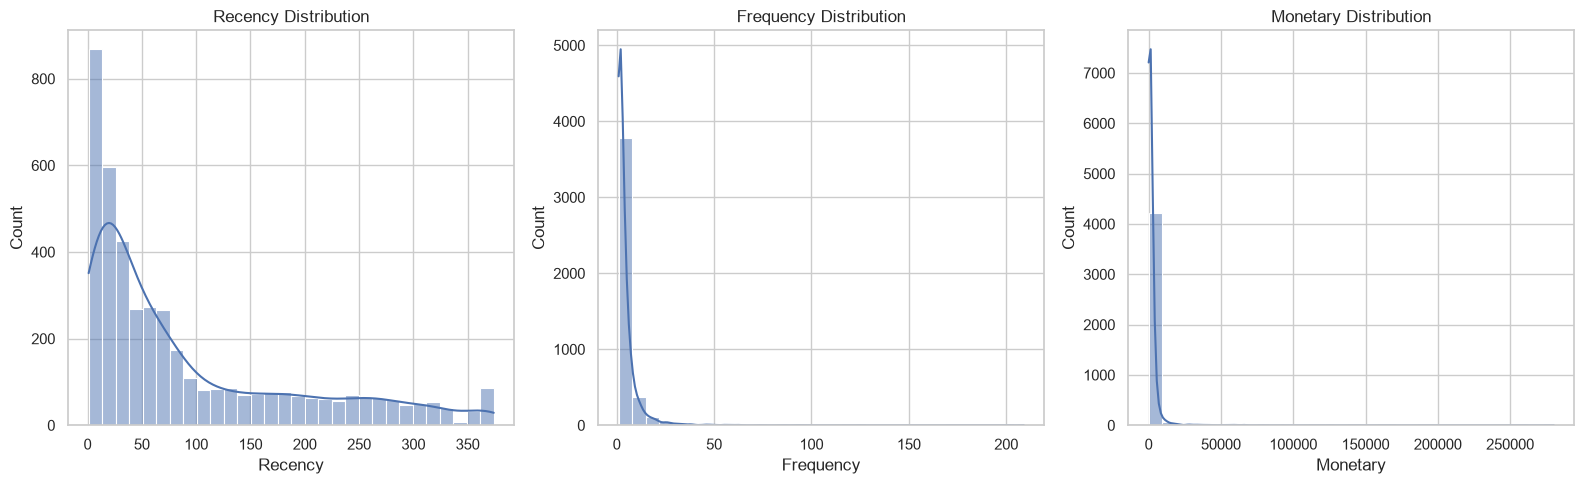

In [46]:

# RFM Distribution Visualization

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(rfm["Recency"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.savefig(
    PLOT_DIR / "rfm_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [47]:

# Save customer-level RFM dataset

rfm_path = REPORT_DIR / "customer_rfm.csv"
rfm.to_csv(rfm_path)

print("RFM Dataset Saved Successfully!")
print("File Location:", rfm_path)


RFM Dataset Saved Successfully!
File Location: d:\Veda_tech_internship\ecommerce-customer-segmentation\reports\customer_rfm.csv


In [48]:

# STEP 7: FEATURE TRANSFORMATION & SCALING

import numpy as np
from sklearn.preprocessing import StandardScaler

# Check skewness before transformation
print("Skewness Before Transformation:")
display(rfm[["Recency", "Frequency", "Monetary"]].skew())


Skewness Before Transformation:


Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

In [49]:

# Apply Log Transformation

rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

print("Transformed RFM Dataset:")
display(rfm_log.head())

print("\nSkewness After Transformation:")
display(rfm_log.skew())


Transformed RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,5.789960,0.693147,11.253955
12347,1.098612,2.079442,8.368925
12348,4.330733,1.609438,7.494564
12349,2.995732,0.693147,7.472245
12350,5.739793,0.693147,5.815324



Skewness After Transformation:


Recency     -0.379169
Frequency    1.208652
Monetary     0.396599
dtype: float64

In [50]:

# Apply Standard Scaling

scaler = StandardScaler()

rfm_scaled_array = scaler.fit_transform(rfm_log)

# Convert scaled array back to DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Scaled RFM Dataset:")
display(rfm_scaled.head())

print("\nScaled Data Statistics:")
display(rfm_scaled.describe().round(2))


Scaled RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514



Scaled Data Statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.68
50%,0.09,-0.36,-0.07
75%,0.84,0.65,0.66
max,1.56,5.86,4.73


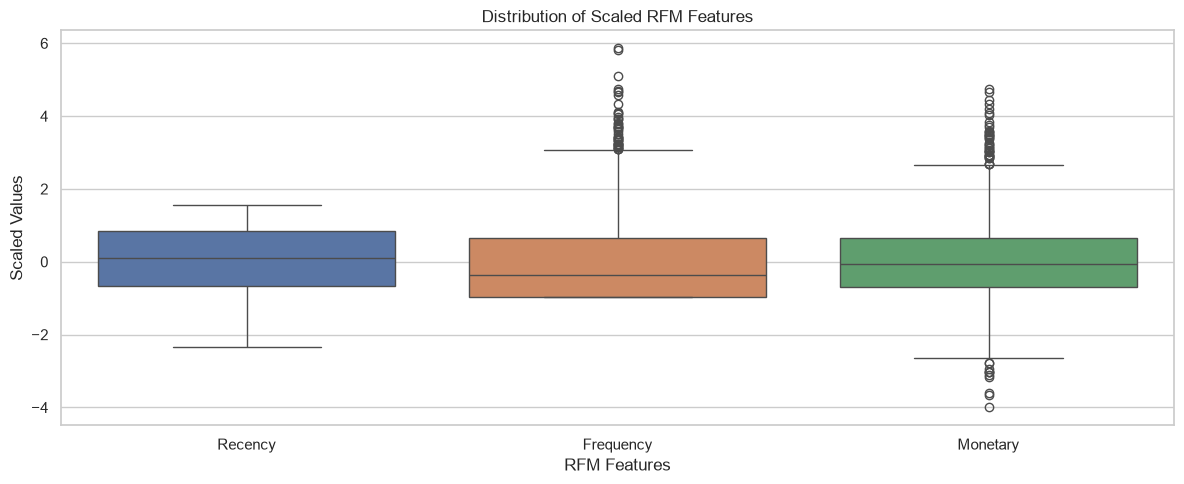

In [51]:

# Visualize Scaled RFM Features

plt.figure(figsize=(12, 5))

sns.boxplot(data=rfm_scaled)

plt.title("Distribution of Scaled RFM Features")
plt.xlabel("RFM Features")
plt.ylabel("Scaled Values")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "scaled_rfm_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [52]:

import joblib

# Save scaled RFM data
rfm_scaled.to_csv(REPORT_DIR / "scaled_rfm.csv")

# Save fitted scaler for future predictions
joblib.dump(scaler, MODEL_DIR / "rfm_scaler.pkl")

print("Feature Scaling Completed Successfully!")
print("Scaled Dataset:", REPORT_DIR / "scaled_rfm.csv")
print("Saved Scaler:", MODEL_DIR / "rfm_scaler.pkl")


Feature Scaling Completed Successfully!
Scaled Dataset: d:\Veda_tech_internship\ecommerce-customer-segmentation\reports\scaled_rfm.csv
Saved Scaler: d:\Veda_tech_internship\ecommerce-customer-segmentation\models\rfm_scaler.pkl


In [53]:

# STEP 8: OPTIMAL CLUSTER SELECTION

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("K-Means and Silhouette Score imported successfully!")


K-Means and Silhouette Score imported successfully!


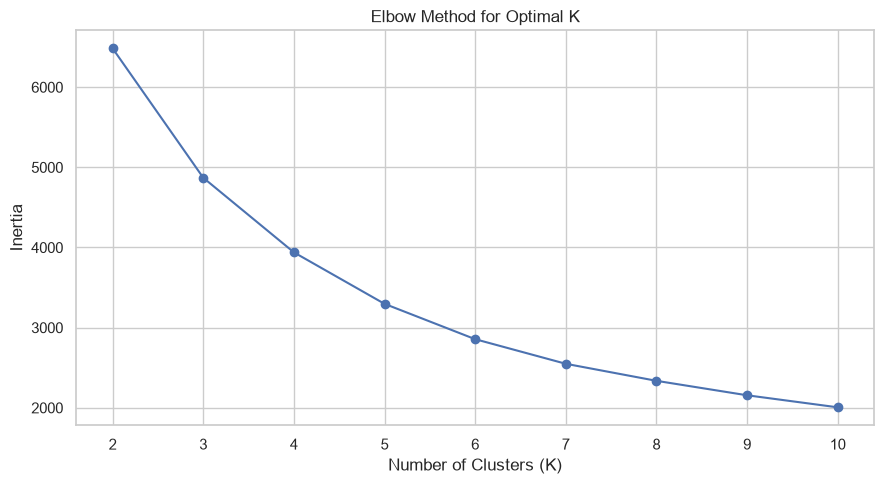

In [54]:

# Elbow Method

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(9, 5))

plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


K = 2, Silhouette Score = 0.4328
K = 3, Silhouette Score = 0.3365
K = 4, Silhouette Score = 0.3375
K = 5, Silhouette Score = 0.3162
K = 6, Silhouette Score = 0.3124
K = 7, Silhouette Score = 0.3092
K = 8, Silhouette Score = 0.3033
K = 9, Silhouette Score = 0.2811
K = 10, Silhouette Score = 0.2767


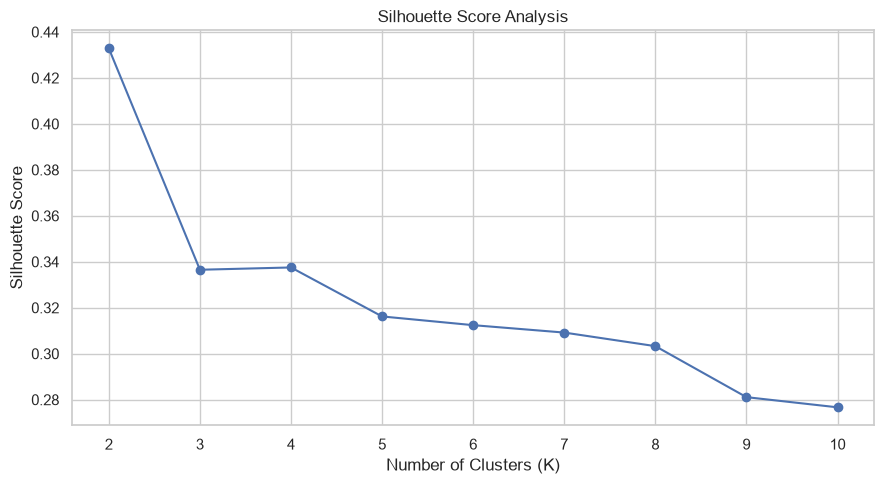

In [55]:

# Calculate Silhouette Scores

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "silhouette_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [56]:
for item in DATA_DIR.iterdir():
    print(item.name, item.is_file(), item.is_dir())

data.csv True False


In [57]:

# Compare clustering results

cluster_evaluation = pd.DataFrame({
    "K": list(range(2, 11)),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
})

display(cluster_evaluation.round(4))

# Best K according to Silhouette Score
best_k_silhouette = cluster_evaluation.loc[
    cluster_evaluation["Silhouette Score"].idxmax(), "K"
]

print("Best K according to Silhouette Score:", int(best_k_silhouette))


,K,Inertia,Silhouette Score
0,2,6483.5894,0.4328
1,3,4869.4886,0.3365
2,4,3939.0494,0.3375
3,5,3296.7087,0.3162
4,6,2855.7641,0.3124
5,7,2548.8202,0.3092
6,8,2336.3411,0.3033
7,9,2156.0057,0.2811
8,10,2005.7462,0.2767


Best K according to Silhouette Score: 2


In [58]:

# Compare clustering results

cluster_evaluation = pd.DataFrame({
    "K": list(range(2, 11)),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
})

display(cluster_evaluation.round(4))

# Best K according to Silhouette Score
best_k_silhouette = cluster_evaluation.loc[
    cluster_evaluation["Silhouette Score"].idxmax(), "K"
]

print("Best K according to Silhouette Score:", int(best_k_silhouette))


,K,Inertia,Silhouette Score
0,2,6483.5894,0.4328
1,3,4869.4886,0.3365
2,4,3939.0494,0.3375
3,5,3296.7087,0.3162
4,6,2855.7641,0.3124
5,7,2548.8202,0.3092
6,8,2336.3411,0.3033
7,9,2156.0057,0.2811
8,10,2005.7462,0.2767


Best K according to Silhouette Score: 2


In [59]:

# Re-assign customer clusters

BEST_K = 2

final_kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

joblib.dump(final_kmeans, MODEL_DIR / "kmeans_model.pkl")

print("Cluster column created successfully!")
print(rfm.columns.tolist())
display(rfm.head())


Cluster column created successfully!
['Recency', 'Frequency', 'Monetary', 'Cluster']


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,1
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,0
12350,310,1,334.40,0


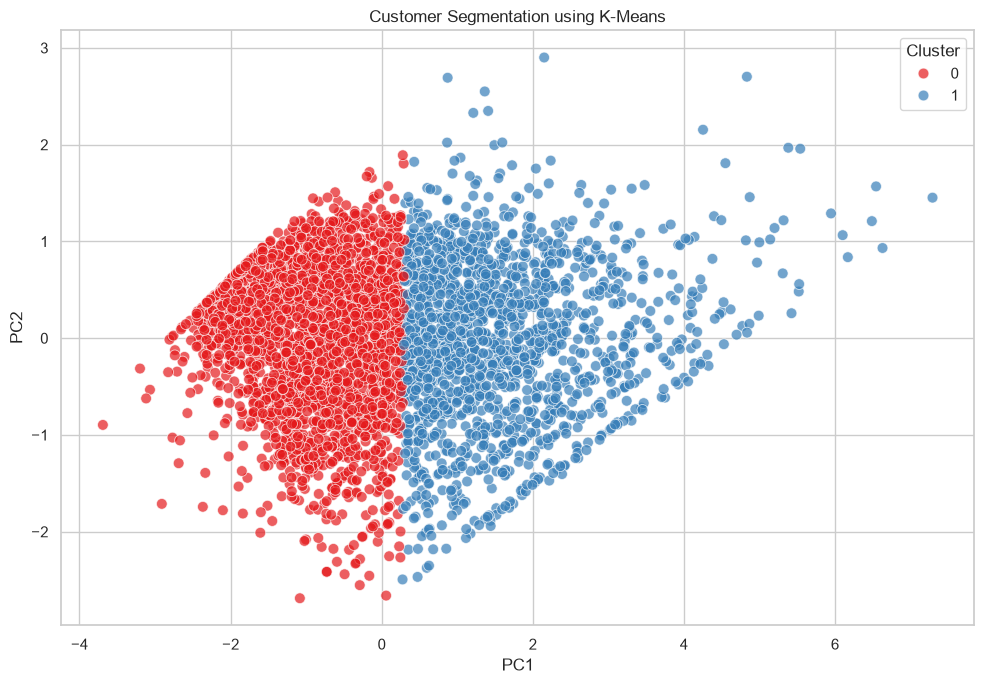

In [60]:

# PCA Cluster Visualization

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

# Attach cluster labels
pca_df["Cluster"] = rfm["Cluster"].values

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=60,
    alpha=0.7
)

plt.title("Customer Segmentation using K-Means")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "customer_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [61]:
rfm.to_csv(REPORT_DIR / "customer_segments.csv")
pca_df.to_csv(REPORT_DIR / "customer_clusters_pca.csv")

print("Customer segmentation files saved successfully!")

Customer segmentation files saved successfully!


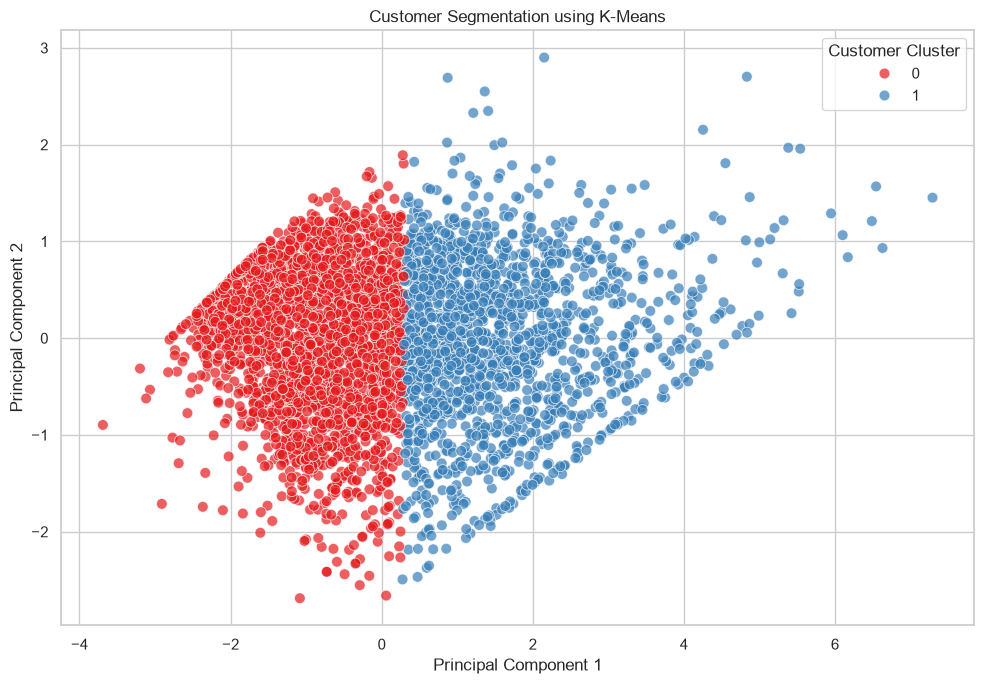

In [62]:

# Visualize Customer Clusters using PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

pca_df["Cluster"] = rfm["Cluster"].values

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=60,
    alpha=0.7
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "customer_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [63]:

# STEP 9: FINAL K-MEANS CLUSTERING

BEST_K = 2

# Train final K-Means model
final_kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

# Generate customer cluster labels
rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

# Save trained model
joblib.dump(
    final_kmeans,
    MODEL_DIR / "kmeans_model.pkl"
)

# Display cluster assignments
print("K-Means Model Trained Successfully!")
print("Number of Clusters:", BEST_K)

display(rfm.head(10))

# Count customers in each cluster
print("\nCustomers in Each Cluster:")
display(rfm["Cluster"].value_counts().sort_index())


K-Means Model Trained Successfully!
Number of Clusters: 2


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,1
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,0
12350,310,1,334.40,0
12352,36,8,2506.04,1
12353,204,1,89.00,0
12354,232,1,1079.40,0
12355,214,1,459.40,0



Customers in Each Cluster:


Cluster
0    2672
1    1666
Name: count, dtype: int64

In [64]:

# STEP 10: CUSTOMER SEGMENT PROFILING

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Cluster": "count"
})

cluster_summary.rename(
    columns={"Cluster": "Customer_Count"},
    inplace=True
)

cluster_summary = cluster_summary.round(2)

display(cluster_summary)

print("\nCustomer Distribution:")
print(
    (rfm["Cluster"].value_counts(normalize=True) * 100)
    .round(2).astype(str) + "%"
)


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,134.09,1.67,495.59,2672
1,25.89,8.44,4539.60,1666



Customer Distribution:
Cluster
0    61.6%
1    38.4%
Name: proportion, dtype: str


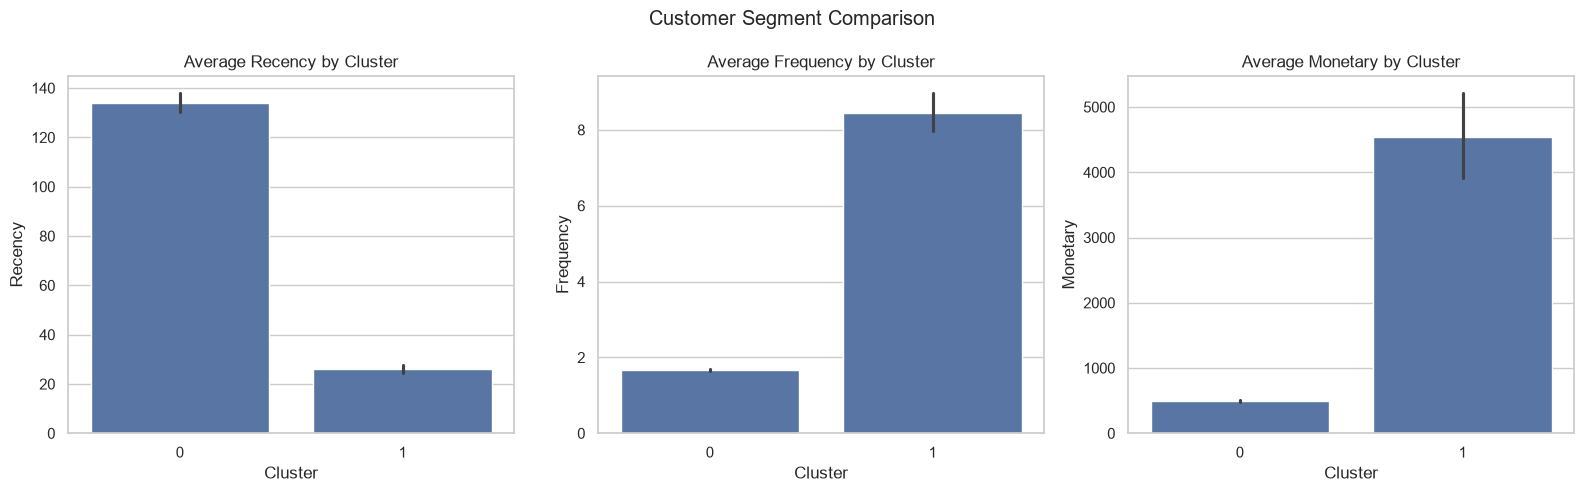

In [65]:

# Cluster-wise RFM comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=rfm, x="Cluster", y="Recency",
    estimator="mean", ax=axes[0]
)
axes[0].set_title("Average Recency by Cluster")

sns.barplot(
    data=rfm, x="Cluster", y="Frequency",
    estimator="mean", ax=axes[1]
)
axes[1].set_title("Average Frequency by Cluster")

sns.barplot(
    data=rfm, x="Cluster", y="Monetary",
    estimator="mean", ax=axes[2]
)
axes[2].set_title("Average Monetary by Cluster")

plt.suptitle("Customer Segment Comparison")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "cluster_rfm_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [66]:

# Identify high-value and low-value cluster

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "CustomerID": "count"
}).rename(columns={"CustomerID": "Customer_Count"})

# Combined activity score:
# Higher frequency + monetary and lower recency = better score
cluster_summary["Activity_Score"] = (
    cluster_summary["Frequency"].rank(pct=True) +
    cluster_summary["Monetary"].rank(pct=True) +
    (1 / cluster_summary["Recency"].clip(lower=1)).rank(pct=True)
) / 3

high_value_cluster = cluster_summary["Activity_Score"].idxmax()

# Assign names
segment_names = {}

for cluster_id in cluster_summary.index:
    if cluster_id == high_value_cluster:
        segment_names[cluster_id] = "High Value Customers"
    else:
        segment_names[cluster_id] = "Low Engagement Customers"

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Segment Mapping:")
print(segment_names)

display(rfm.head(10))


KeyError: "Label(s) ['CustomerID'] do not exist"

In [ ]:
Segment Mapping:
{0: 'High Value Customers',
 1: 'Low Engagement Customers'}

SyntaxError: invalid syntax (1503308448.py, line 1)

In [ ]:

# STEP 10.5: FINAL CUSTOMER SEGMENT SUMMARY

final_segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(final_segment_summary)

# Save report
final_segment_summary.to_csv(
    REPORT_DIR / "final_segment_summary.csv"
)

print("Final Segment Analysis Saved Successfully!")


KeyError: 'Segment'

In [ ]:
print(rfm.columns.tolist())

['Recency', 'Frequency', 'Monetary']


In [ ]:

# Recreate K-Means clusters

BEST_K = 2

final_kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

joblib.dump(final_kmeans, MODEL_DIR / "kmeans_model.pkl")

print("Columns:", rfm.columns.tolist())
display(rfm.head())


Columns: ['Recency', 'Frequency', 'Monetary', 'Cluster']


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,1
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,0
12350,310,1,334.40,0


In [ ]:

# Create business-friendly customer segments

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
})

cluster_summary["Activity_Score"] = (
    cluster_summary["Frequency"].rank(pct=True) +
    cluster_summary["Monetary"].rank(pct=True) +
    (1 / cluster_summary["Recency"].clip(lower=1)).rank(pct=True)
) / 3

high_value_cluster = cluster_summary["Activity_Score"].idxmax()

segment_names = {
    cluster_id: (
        "High Value Customers"
        if cluster_id == high_value_cluster
        else "Low Engagement Customers"
    )
    for cluster_id in cluster_summary.index
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Segment Mapping:", segment_names)
display(rfm.head())


Segment Mapping: {0: 'Low Engagement Customers', 1: 'High Value Customers'}


,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,1,High Value Customers
12347,2,7,4310.00,1,High Value Customers
12348,75,4,1797.24,1,High Value Customers
12349,19,1,1757.55,0,Low Engagement Customers
12350,310,1,334.40,0,Low Engagement Customers


In [ ]:

final_segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(final_segment_summary)

final_segment_summary.to_csv(
    REPORT_DIR / "final_segment_summary.csv"
)

rfm.to_csv(REPORT_DIR / "customer_segments.csv")

print("Customer Segmentation Completed Successfully!")


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,
High Value Customers,1666,25.89,8.44,4539.60
Low Engagement Customers,2672,134.09,1.67,495.59


Customer Segmentation Completed Successfully!


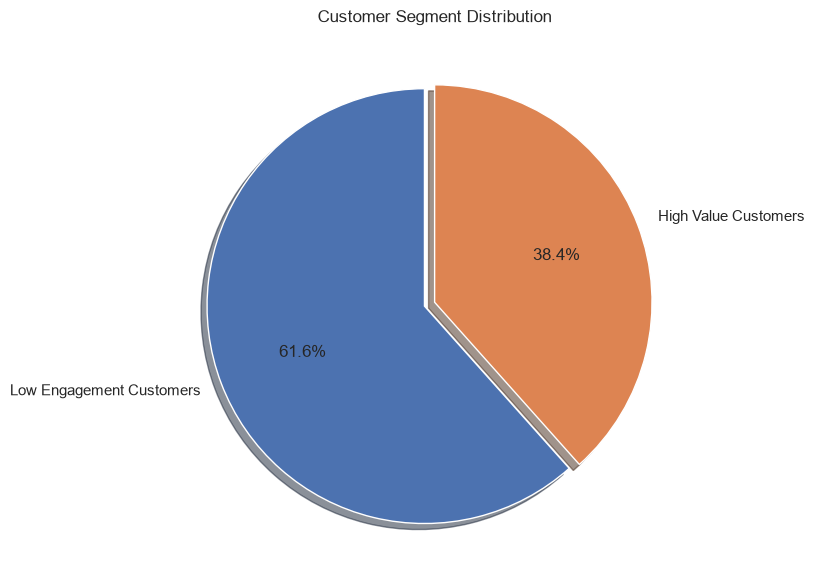

In [ ]:

# Customer Segment Distribution

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(9, 6))

plt.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05, 0],
    shadow=True
)

plt.title("Customer Segment Distribution")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [ ]:

# STEP 11: PRODUCT RECOMMENDATION SYSTEM

# Create product-invoice matrix
product_invoice_matrix = df_clean.pivot_table(
    index="StockCode",
    columns="InvoiceNo",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

print("Product-Invoice Matrix Shape:", product_invoice_matrix.shape)

display(product_invoice_matrix.head())


Product-Invoice Matrix Shape: (3665, 18532)


InvoiceNo,536365,536366,536367,536368,536369,536370,536371,536372,536373,536374,...,581578,581579,581580,581581,581582,581583,581584,581585,581586,581587
StockCode,,,,,,,,,,,,,,,,,,,,,
10002,0,0,0,0,0,48,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10080,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10120,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10123C,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10124A,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

from sklearn.metrics.pairwise import cosine_similarity

# Calculate product similarity
product_similarity = cosine_similarity(product_invoice_matrix)

product_similarity_df = pd.DataFrame(
    product_similarity,
    index=product_invoice_matrix.index,
    columns=product_invoice_matrix.index
)

print("Cosine Similarity Matrix Created!")
display(product_similarity_df.iloc[:5, :5])


Cosine Similarity Matrix Created!


StockCode,10002,10080,10120,10123C,10124A
StockCode,,,,,
10002,1.000000,0.0,0.001991,0.001420,0.0
10080,0.000000,1.0,0.000000,0.000000,0.0
10120,0.001991,0.0,1.000000,0.005542,0.0
10123C,0.001420,0.0,0.005542,1.000000,0.0
10124A,0.000000,0.0,0.000000,0.000000,1.0


In [ ]:

# Product Recommendation Function

def recommend_products(product_code, top_n=5):

    if product_code not in product_similarity_df.index:
        return "Product not found in recommendation database."

    similar_products = product_similarity_df[product_code].sort_values(
        ascending=False
    )

    # Exclude the selected product itself
    similar_products = similar_products.drop(product_code)

    recommendations = similar_products.head(top_n).index

    result = df_clean[
        df_clean["StockCode"].isin(recommendations)
    ][["StockCode", "Description"]].drop_duplicates()

    return result.head(top_n)


# Test recommendation system
sample_product = product_invoice_matrix.index[0]

print("Selected Product:", sample_product)
display(recommend_products(sample_product, top_n=5))


Selected Product: 10002


,StockCode,Description
203,85014A,BLACK/BLUE POLKADOT UMBRELLA
3594,22559,SEASIDE FLYING DISC
92438,23003,TRAVEL CARD WALLET VINTAGE ROSE
116712,84535A,ENGLISH ROSE NOTEBOOK A6 SIZE
145770,16202E,BLACK PHOTO ALBUM


In [ ]:

# Save product similarity matrix
product_similarity_df.to_csv(
    REPORT_DIR / "product_similarity_matrix.csv"
)

print("Product Recommendation System Saved Successfully!")


Product Recommendation System Saved Successfully!


In [67]:

# STEP 11: PRODUCT RECOMMENDATION SYSTEM

# Create product-invoice matrix
product_invoice_matrix = df_clean.pivot_table(
    index="StockCode",
    columns="InvoiceNo",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

print("Product-Invoice Matrix Shape:", product_invoice_matrix.shape)
print("\nTotal Products:", product_invoice_matrix.shape[0])
print("Total Transactions:", product_invoice_matrix.shape[1])

display(product_invoice_matrix.head())


Product-Invoice Matrix Shape: (3665, 18532)

Total Products: 3665
Total Transactions: 18532


InvoiceNo,536365,536366,536367,536368,536369,536370,536371,536372,536373,536374,...,581578,581579,581580,581581,581582,581583,581584,581585,581586,581587
StockCode,,,,,,,,,,,,,,,,,,,,,
10002,0,0,0,0,0,48,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10080,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10120,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10123C,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10124A,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [68]:

from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between products
product_similarity = cosine_similarity(product_invoice_matrix)

# Convert similarity array into DataFrame
product_similarity_df = pd.DataFrame(
    product_similarity,
    index=product_invoice_matrix.index,
    columns=product_invoice_matrix.index
)

print("Product Similarity Matrix Created!")
print("Similarity Matrix Shape:", product_similarity_df.shape)

display(product_similarity_df.iloc[:5, :5])


Product Similarity Matrix Created!
Similarity Matrix Shape: (3665, 3665)


StockCode,10002,10080,10120,10123C,10124A
StockCode,,,,,
10002,1.000000,0.0,0.001991,0.001420,0.0
10080,0.000000,1.0,0.000000,0.000000,0.0
10120,0.001991,0.0,1.000000,0.005542,0.0
10123C,0.001420,0.0,0.005542,1.000000,0.0
10124A,0.000000,0.0,0.000000,0.000000,1.0


In [69]:

# Product Recommendation Function

def recommend_products(product_code, top_n=5):

    if product_code not in product_similarity_df.index:
        return "Product not found in recommendation database."

    # Get similarity scores
    similarity_scores = product_similarity_df[product_code]

    # Sort by similarity
    similar_products = similarity_scores.sort_values(
        ascending=False
    )

    # Remove selected product
    similar_products = similar_products.drop(product_code)

    # Select top recommendations
    recommended_codes = similar_products.head(top_n).index

    # Get product descriptions
    recommendations = (
        df_clean[df_clean["StockCode"].isin(recommended_codes)]
        [["StockCode", "Description"]]
        .drop_duplicates(subset=["StockCode"])
    )

    # Preserve recommendation ranking
    recommendations["StockCode"] = recommendations["StockCode"].astype(
        str
    )

    ranking = {str(code): i + 1 for i, code in enumerate(recommended_codes)}

    recommendations["Rank"] = recommendations["StockCode"].map(ranking)

    return recommendations.sort_values("Rank").reset_index(drop=True)


print("Recommendation Function Created Successfully!")


Recommendation Function Created Successfully!


In [70]:

# Test recommendation engine

sample_product = product_invoice_matrix.index[0]

print("Selected Product Code:", sample_product)
print("\nRecommended Products:")

display(
    recommend_products(sample_product, top_n=5)
)


Selected Product Code: 10002

Recommended Products:


,StockCode,Description,Rank
0,85014A,BLACK/BLUE POLKADOT UMBRELLA,1
1,22559,SEASIDE FLYING DISC,2
2,84535A,ENGLISH ROSE NOTEBOOK A6 SIZE,3
3,16202E,BLACK PHOTO ALBUM,4
4,23003,TRAVEL CARD WALLET VINTAGE ROSE,5


In [71]:

# Save recommendation similarity matrix

product_similarity_df.to_csv(
    REPORT_DIR / "product_similarity_matrix.csv"
)

print("Product Similarity Matrix Saved Successfully!")


Product Similarity Matrix Saved Successfully!


In [72]:

# STEP 12: BUSINESS RECOMMENDATIONS

business_recommendations = {
    "High Value Customers": [
        "Provide exclusive loyalty rewards and membership benefits.",
        "Offer personalized product recommendations.",
        "Provide early access to new products and special offers.",
        "Encourage repeat purchases through premium loyalty programs.",
        "Maintain engagement through personalized email campaigns."
    ],

    "Low Engagement Customers": [
        "Launch win-back campaigns with personalized discounts.",
        "Offer limited-time promotional offers.",
        "Send reminders about previously purchased products.",
        "Recommend popular and frequently purchased products.",
        "Use email campaigns to encourage repeat purchases."
    ]
}

for segment, recommendations in business_recommendations.items():

    print("\n", "=" * 55)
    print(segment.upper())
    print("=" * 55)

    for i, recommendation in enumerate(recommendations, 1):
        print(f"{i}. {recommendation}")



HIGH VALUE CUSTOMERS
1. Provide exclusive loyalty rewards and membership benefits.
2. Offer personalized product recommendations.
3. Provide early access to new products and special offers.
4. Encourage repeat purchases through premium loyalty programs.
5. Maintain engagement through personalized email campaigns.

LOW ENGAGEMENT CUSTOMERS
1. Launch win-back campaigns with personalized discounts.
2. Offer limited-time promotional offers.
3. Send reminders about previously purchased products.
4. Recommend popular and frequently purchased products.
5. Use email campaigns to encourage repeat purchases.


In [73]:

# Convert recommendations into a structured DataFrame

recommendation_rows = []

for segment, recommendations in business_recommendations.items():

    for recommendation in recommendations:

        recommendation_rows.append({
            "Customer_Segment": segment,
            "Business_Recommendation": recommendation
        })

business_recommendation_df = pd.DataFrame(recommendation_rows)

display(business_recommendation_df)

# Save report
business_recommendation_df.to_csv(
    REPORT_DIR / "business_recommendations.csv",
    index=False
)

print("Business Recommendations Report Saved!")


,Customer_Segment,Business_Recommendation
0,High Value Customers,Provide exclusive loyalty rewards and membersh...
1,High Value Customers,Offer personalized product recommendations.
2,High Value Customers,Provide early access to new products and speci...
3,High Value Customers,Encourage repeat purchases through premium loy...
4,High Value Customers,Maintain engagement through personalized email...
5,Low Engagement Customers,Launch win-back campaigns with personalized di...
6,Low Engagement Customers,Offer limited-time promotional offers.
7,Low Engagement Customers,Send reminders about previously purchased prod...
8,Low Engagement Customers,Recommend popular and frequently purchased pro...
9,Low Engagement Customers,Use email campaigns to encourage repeat purcha...


Business Recommendations Report Saved!


In [78]:

# STEP 13: FINAL PROJECT SUMMARY

total_customers = rfm.index.nunique()
total_transactions = df_clean["InvoiceNo"].nunique()
total_products = df_clean["StockCode"].nunique()
total_revenue = df_clean["TotalAmount"].sum()

final_project_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Total Customers",
        "Total Products",
        "Total Revenue",
        "Number of Clusters",
        "High Value Customers",
        "Low Engagement Customers"
    ],
    "Value": [
        total_transactions,
        total_customers,
        total_products,
        round(total_revenue, 2),
        BEST_K,
        int((rfm["Segment"] == "High Value Customers").sum()),
        int((rfm["Segment"] == "Low Engagement Customers").sum())
    ]
})

display(final_project_summary)

final_project_summary.to_csv(
    REPORT_DIR / "final_project_summary.csv",
    index=False
)

print("Final Project Summary Saved!")


,Metric,Value
0,Total Transactions,18532.00
1,Total Customers,4338.00
2,Total Products,3665.00
3,Total Revenue,8887208.89
4,Number of Clusters,2.00
5,High Value Customers,1666.00
6,Low Engagement Customers,2672.00


Final Project Summary Saved!


In [75]:
print(rfm.columns.tolist())

['Recency', 'Frequency', 'Monetary', 'Cluster']


In [76]:

# REPAIR: RESTORE CUSTOMER CLUSTERS AND SEGMENTS

# Step 1: Ensure Cluster column exists
if "Cluster" not in rfm.columns:

    rfm["Cluster"] = final_kmeans.predict(rfm_scaled)

# Step 2: Calculate cluster profiles
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
})

# Step 3: Calculate activity score
cluster_summary["Activity_Score"] = (
    cluster_summary["Frequency"].rank(pct=True) +
    cluster_summary["Monetary"].rank(pct=True) +
    (1 / cluster_summary["Recency"].clip(lower=1)).rank(pct=True)
) / 3

# Step 4: Identify high-value cluster
high_value_cluster = cluster_summary["Activity_Score"].idxmax()

# Step 5: Assign segment names
segment_names = {
    cluster_id: (
        "High Value Customers"
        if cluster_id == high_value_cluster
        else "Low Engagement Customers"
    )
    for cluster_id in cluster_summary.index
}

# Step 6: Create Segment column
rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Cluster and Segment columns restored!")
print(rfm.columns.tolist())

display(rfm.head())


Cluster and Segment columns restored!
['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']


,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,1,High Value Customers
12347,2,7,4310.00,1,High Value Customers
12348,75,4,1797.24,1,High Value Customers
12349,19,1,1757.55,0,Low Engagement Customers
12350,310,1,334.40,0,Low Engagement Customers


In [77]:
display(rfm["Segment"].value_counts())

Segment
Low Engagement Customers    2672
High Value Customers        1666
Name: count, dtype: int64

In [79]:

# Verify generated reports

print("REPORT FILES")
print("=" * 40)

for file in sorted(REPORT_DIR.iterdir()):
    if file.is_file():
        print(file.name)


REPORT FILES
business_recommendations.csv
customer_clusters_pca.csv
customer_rfm.csv
customer_segments.csv
final_project_summary.csv
final_segment_summary.csv
product_similarity_matrix.csv
scaled_rfm.csv


In [80]:

# STEP 14: SAVE FINAL MODEL ARTIFACTS

import joblib

# Save clustering model
joblib.dump(
    final_kmeans,
    MODEL_DIR / "kmeans_model.pkl"
)

# Save feature scaler
joblib.dump(
    scaler,
    MODEL_DIR / "rfm_scaler.pkl"
)

# Save recommendation matrix
joblib.dump(
    product_similarity_df,
    MODEL_DIR / "product_similarity.pkl"
)

print("All Model Artifacts Saved Successfully!")

for file in MODEL_DIR.iterdir():
    if file.is_file():
        print(file.name)


All Model Artifacts Saved Successfully!
kmeans_model.pkl
product_similarity.pkl
rfm_scaler.pkl


In [81]:

# Load saved models
loaded_kmeans = joblib.load(
    MODEL_DIR / "kmeans_model.pkl"
)

loaded_scaler = joblib.load(
    MODEL_DIR / "rfm_scaler.pkl"
)

# Test prediction on existing customer data
test_data = rfm[["Recency", "Frequency", "Monetary"]].head(5)

test_scaled = loaded_scaler.transform(
    np.log1p(test_data)
)

predictions = loaded_kmeans.predict(test_scaled)

print("Model Testing Results:")
print("Predicted Clusters:", predictions)

print("\nActual Clusters:")
print(rfm["Cluster"].head(5).values)


Model Testing Results:
Predicted Clusters: [1 1 1 0 0]

Actual Clusters:
[1 1 1 0 0]


In [82]:

# FINAL PROJECT VERIFICATION

print("=" * 55)
print("E-COMMERCE CUSTOMER SEGMENTATION PROJECT")
print("FINAL VERIFICATION")
print("=" * 55)

print("Total Customers:", rfm.index.nunique())
print("Total Transactions:", df_clean["InvoiceNo"].nunique())
print("Total Products:", df_clean["StockCode"].nunique())
print("Selected Clusters:", BEST_K)

print("\nCustomer Segments:")
print(rfm["Segment"].value_counts())

print("\nModel Files:")
for file in MODEL_DIR.iterdir():
    if file.is_file():
        print("-", file.name)

print("\nReport Files:")
for file in REPORT_DIR.iterdir():
    if file.is_file():
        print("-", file.name)

print("\nVisualization Files:")
for file in PLOT_DIR.iterdir():
    if file.is_file():
        print("-", file.name)

print("\nPROJECT VERIFICATION COMPLETED!")


E-COMMERCE CUSTOMER SEGMENTATION PROJECT
FINAL VERIFICATION
Total Customers: 4338
Total Transactions: 18532
Total Products: 3665
Selected Clusters: 2

Customer Segments:
Segment
Low Engagement Customers    2672
High Value Customers        1666
Name: count, dtype: int64

Model Files:
- kmeans_model.pkl
- product_similarity.pkl
- rfm_scaler.pkl

Report Files:
- business_recommendations.csv
- customer_clusters_pca.csv
- customer_rfm.csv
- customer_segments.csv
- final_project_summary.csv
- final_segment_summary.csv
- product_similarity_matrix.csv
- scaled_rfm.csv

Visualization Files:
- cluster_rfm_comparison.png
- customer_clusters_pca.png
- customer_segment_distribution.png
- elbow_method.png
- rfm_distribution.png
- scaled_rfm_distribution.png
- silhouette_analysis.png

PROJECT VERIFICATION COMPLETED!
